In [25]:
import pandas as pd 
import requests 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [4]:
PAGINAS = {
    "GTA V": "Grand_Theft_Auto_V",
    "GTA VI": "Grand_Theft_Auto_VI",
}
INICIO = "20231201"  # mês do primeiro trailer do GTA VI
FIM = "20261119"     # dia do lançamento

URL = (
    "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
    "en.wikipedia/all-access/user/{pagina}/daily/{ini}/{fim}"
)
# A Wikimedia exige um User-Agent identificado
HEADERS = {"User-Agent": "analise-gta/1.0 (estudo pessoal de dados)"}

In [5]:
linhas = []
for nome, pagina in PAGINAS.items():
    r = requests.get(URL.format(pagina=pagina, ini=INICIO, fim=FIM), headers=HEADERS, timeout=60)
    r.raise_for_status()
    for item in r.json()["items"]:
        linhas.append({
            "data": pd.to_datetime(item["timestamp"], format="%Y%m%d00"), #diz aos pandas um horário fixo
            "pagina": nome, 
            "acessos": item["views"],
        })

df = pd.DataFrame(linhas)
df.head()

,data,pagina,acessos
0,2023-12-01,GTA V,19965
1,2023-12-02,GTA V,21681
2,2023-12-03,GTA V,19795
3,2023-12-04,GTA V,37531
4,2023-12-05,GTA V,168422


In [7]:
df.to_csv("gta_pageviews.csv", index=False)
print(len(df), "linhas salvas")

2168 linhas salvas


In [8]:
#achando os dias de maior interesse 

picos = (
    df.sort_values("acessos", ascending=False)
    .groupby("pagina")
    .head(5)
    .sort_values(["pagina", "acessos"], ascending=[True, False])
)

picos

,data,pagina,acessos
4,2023-12-05,GTA V,168422
1083,2026-11-18,GTA V,81349
5,2023-12-06,GTA V,78381
6,2023-12-07,GTA V,49724
7,2023-12-08,GTA V,38369
2167,2026-11-18,GTA VI,519632
1088,2023-12-05,GTA VI,341519
1089,2023-12-06,GTA VI,153488
2166,2026-11-17,GTA VI,153037
2165,2026-11-16,GTA VI,106689


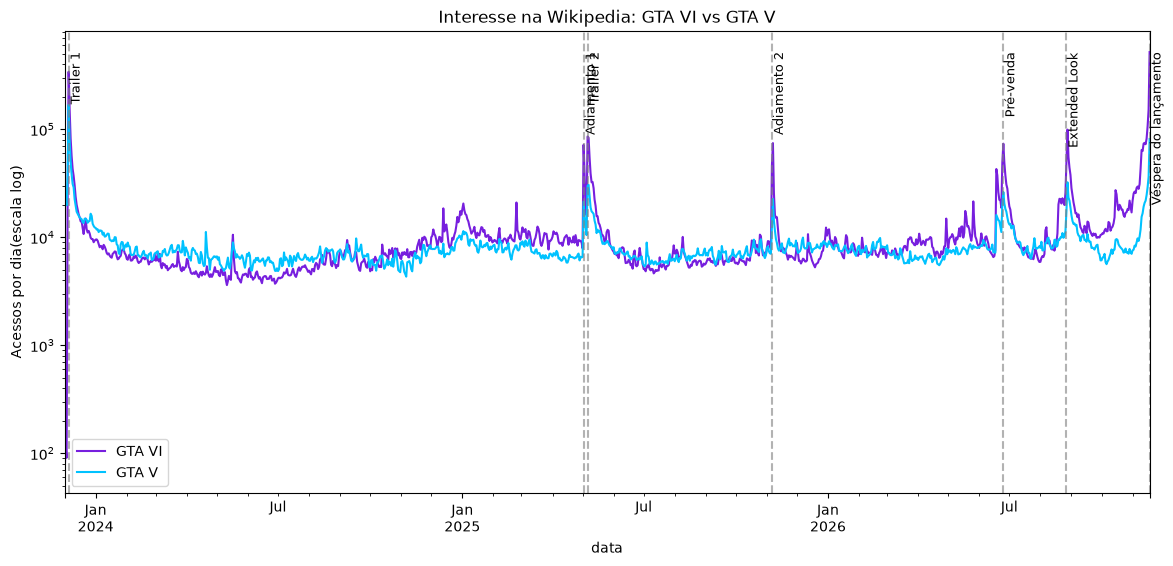

In [29]:
tabela = df.pivot(index="data", columns="pagina", values="acessos") #uma coluna por jogo, uma linha por dia
eventos1 = [
    ("2023-12-05", "Trailer 1"),
    ("2025-05-02", "Adiamento 1"),
    ("2025-05-06", "Trailer 2"),
    ("2025-11-06", "Adiamento 2"),
]

fig, ax = plt.subplots(figsize=(14,6))
tabela["GTA VI"].plot(ax=ax, label="GTA VI", color="#771fde")
tabela["GTA V"].plot(ax=ax, label="GTA V", color="#00c2ff")  

for data, rotulo in eventos: 
    ax.axvline(pd.to_datetime(data), color="gray", linestyle="--", alpha=0.6) #axis vertical line
    ax.text(pd.to_datetime(data), ax.get_ylim()[1] * 0.95, rotulo, rotation=90, va="top", fontsize=9)

ax.set_yscale("log")
ax.set_title("Interesse na Wikipedia: GTA VI vs GTA V")
ax.set_ylabel("Acessos por dia(escala log)")
ax.legend()
plt.show()

In [20]:
#separando os 10 dias com mais acessos do GTA VI, em ordem de data
(
    df[df["pagina"] == "GTA VI"]
    .sort_values("acessos", ascending=False)
    .head(10)
    .sort_values("data")
)

,data,pagina,acessos
1088,2023-12-05,GTA VI,341519
1089,2023-12-06,GTA VI,153488
1090,2023-12-07,GTA VI,82441
1606,2025-05-06,GTA VI,85823
1607,2025-05-07,GTA VI,83648
2085,2026-08-28,GTA VI,99406
2164,2026-11-15,GTA VI,82149
2165,2026-11-16,GTA VI,106689
2166,2026-11-17,GTA VI,153037
2167,2026-11-18,GTA VI,519632


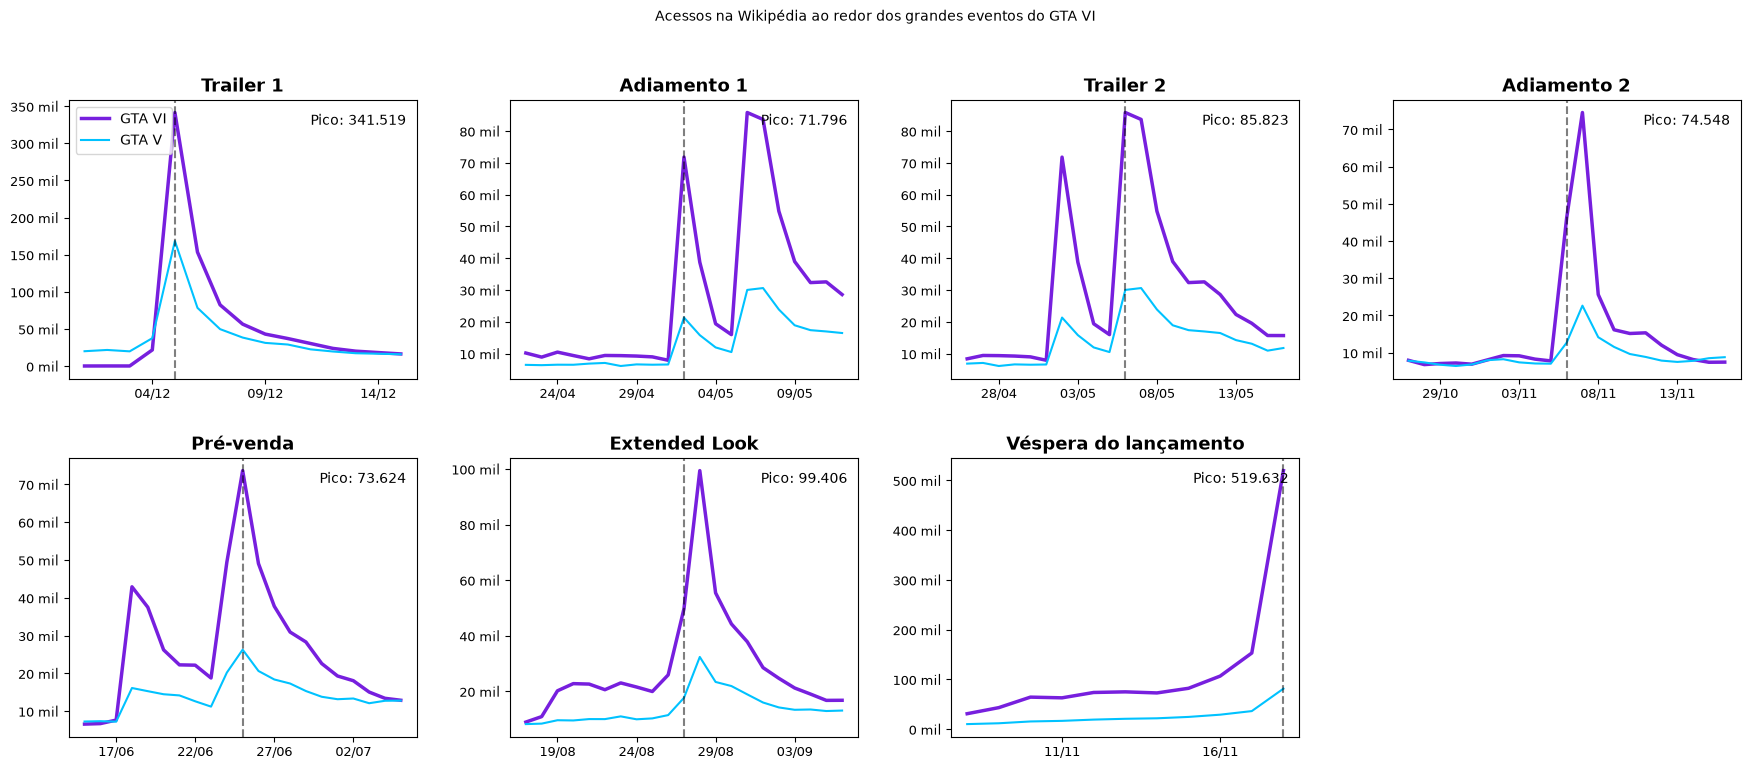

In [33]:
eventos2 = [
    ("2023-12-05", "Trailer 1"),
    ("2025-05-02", "Adiamento 1"),
    ("2025-05-06", "Trailer 2"),
    ("2025-11-06", "Adiamento 2"),
    ("2026-06-25", "Pré-venda"),
    ("2026-08-27", "Extended Look"),
    ("2026-11-18", "Véspera do lançamento"),
]

fig, axes = plt.subplots(2, 4, figsize=(18,8))
axes = axes.flatten()

for ax, (data, titulo) in zip(axes, eventos):
    d = pd.to_datetime(data)
    recorte = tabela[d - pd.Timedelta(days=10): d + pd.Timedelta(days=10)]
    ax.plot(recorte.index, recorte["GTA VI"], color= "#771fde", linewidth=2.5, label="GTA VI")
    ax.plot(recorte.index, recorte["GTA V"], color= "#00c2ff", linewidth=1.5, label="GTA V")
    ax.axvline(d, color="black", linestyle="--", alpha=0.5)
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, pos: f"{int(v / 1000)} mil")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.tick_params(labelsize=9)
    pico = recorte["GTA VI"][d - pd.Timedelta(days=1): d + pd.Timedelta(days=1)].max()
    ax.text(0.97, 0.95, f"Pico: {pico:,}".replace(",", "."), transform=ax.transAxes,
            ha="right", va="top", fontsize=10)

axes[0].legend(loc="upper left", fontsize=10)
axes[-1].axis("off")
fig.suptitle("Acessos na Wikipédia ao redor dos grandes eventos do GTA VI", fontsize=10)
fig.tight_layout(pad=2.5)
plt.show()

